# Solver harness

Runs all solvers from `solvers.py` on the same problem and compares them side by side.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
# project root → privateggm importable
sys.path.insert(0, os.path.dirname(os.path.dirname(os.getcwd())))

import numpy as np
import matplotlib.pyplot as plt

from privateggm import solve


## Problem

In [2]:
def make_problem(d=32, fraction_offdiag=0.2, tau_diag=0.2, seed=42):
    """Random covariance estimation problem."""
    rng = np.random.default_rng(seed)
    Q, _ = np.linalg.qr(rng.standard_normal((d, d)))
    eigvals = np.clip(np.exp(rng.standard_normal(d)), 0.1, 10.0)
    Sigma_true = Q @ np.diag(eigvals) @ Q.T

    n_off = int(fraction_offdiag * (d * (d - 1) // 2))
    diag_inds = [(i, i) for i in range(d)]
    pool = [(i, j) for i in range(d) for j in range(i + 1, d)]
    chosen = rng.choice(len(pool), min(n_off, len(pool)), replace=False)
    off_inds = [pool[k] for k in chosen]

    inds = np.array(diag_inds + off_inds)
    rows, cols = inds[:, 0], inds[:, 1]
    tau  = np.array([tau_diag] * d + [tau_diag * 2.0] * n_off)
    vals = Sigma_true[rows, cols] + rng.normal(0, tau)

    return Sigma_true, rows, cols, vals, tau


d        = 256
tau_diag = 1.0    # increase for high-noise (PSD-boundary) regime
avg_degree = 2.0

Sigma_true, rows, cols, vals, tau = make_problem(d=d, tau_diag=tau_diag, fraction_offdiag=avg_degree / d)
print(f'd = {d},  |S| = {len(vals)}  ({d} diag + {len(vals)-d} off-diag)')
print(f'True eigenvalue range: [{np.linalg.eigvalsh(Sigma_true).min():.3f}, {np.linalg.eigvalsh(Sigma_true).max():.3f}]')


d = 256,  |S| = 511  (256 diag + 255 off-diag)
True eigenvalue range: [0.100, 10.000]


## Run all solvers

In [3]:
decompose_method = 'blocks'   # None | 'diag' | 'blocks'
verbose = True

print('pgd ...')
S_pgd, h_pgd = solve(rows, cols, vals, tau, d, solver='pgd', decompose=decompose_method, max_iters=2000, verbose=verbose)

print('pgd_maxent ...')
S_pgm, h_pgm = solve(rows, cols, vals, tau, d, solver='pgd_maxent', decompose=decompose_method, pgd_iters=2000, lbfgs_iters=1000, verbose=verbose)

print('dr_splitting ...')
S_dr, h_dr = solve(rows, cols, vals, tau, d, solver='dr_splitting', decompose=decompose_method, verbose=verbose)

print('ipm_chol ...')
S_ipm, h_ipm = solve(rows, cols, vals, tau, d, solver='ipm_chol', decompose=decompose_method, verbose=verbose)

print('ipm_chol_sparse ...')
S_ipm_sp, h_ipm_sp = solve(rows, cols, vals, tau, d, solver='ipm_chol_sparse', decompose=decompose_method, verbose=verbose)

print('done.')


pgd ...
decompose='blocks': 37 singletons, 9 blocks [sizes: 197, 5, 4, 3, 2, 2, 2, 2, 2]
pgd_maxent ...
decompose='blocks': 37 singletons, 9 blocks [sizes: 197, 5, 4, 3, 2, 2, 2, 2, 2]
dr_splitting ...
decompose='blocks': 37 singletons, 9 blocks [sizes: 197, 5, 4, 3, 2, 2, 2, 2, 2]
ipm_chol ...
decompose='blocks': 37 singletons, 9 blocks [sizes: 197, 5, 4, 3, 2, 2, 2, 2, 2]
ipm_chol_sparse ...
decompose='blocks': 37 singletons, 9 blocks [sizes: 197, 5, 4, 3, 2, 2, 2, 2, 2]
done.


## Comparison table

In [4]:
w = 1.0 / tau ** 2;  w /= w.max()

def weighted_obj(S):
    r = S[rows, cols] - vals
    return float(np.sum(w * r ** 2))

results = [
    ('pgd',        S_pgd,  h_pgd),
    ('pgd_maxent', S_pgm,  h_pgm),
    ('dr_splitting', S_dr, h_dr),
    ('ipm_chol',   S_ipm,  h_ipm),
    ('ipm_chol_sparse', S_ipm_sp, h_ipm_sp),
]

hdr = f"  {'solver':<20} {'obj':>12} {'entropy':>12} {'frob_err':>12} {'min_eig':>10} {'time(s)':>10} {'iters':>7}"
print(hdr)
print('-' * len(hdr))
for name, S, h in results:
    print(f"  {name:<20}"
          f" {weighted_obj(S):>12.4e}"
          f" {np.linalg.slogdet(S)[1]:>12.4f}"
          f" {np.linalg.norm(Sigma_true - S, 'fro'):>12.4f}"
          f" {np.linalg.eigvalsh(S).min():>10.2e}"
          f" {h[-1]['time']:>10.3f}"
          f" {len(h):>7d}")


  solver                        obj      entropy     frob_err    min_eig    time(s)   iters
-------------------------------------------------------------------------------------------
  pgd                    7.0322e+01   -2509.8763      68.2504   1.00e-10      5.702    2000
  pgd_maxent             2.2639e+02    -284.1999      87.4830   1.00e-10      6.102    2032
  dr_splitting           7.0277e+01   -2127.6762      85.2809  -4.66e-09     13.710     200
  ipm_chol               7.0243e+01   -1834.2632      87.9986   6.00e-12      3.657      28
  ipm_chol_sparse        7.0244e+01   -1826.6258      93.5957   6.14e-12     11.238      28


## Convergence plots

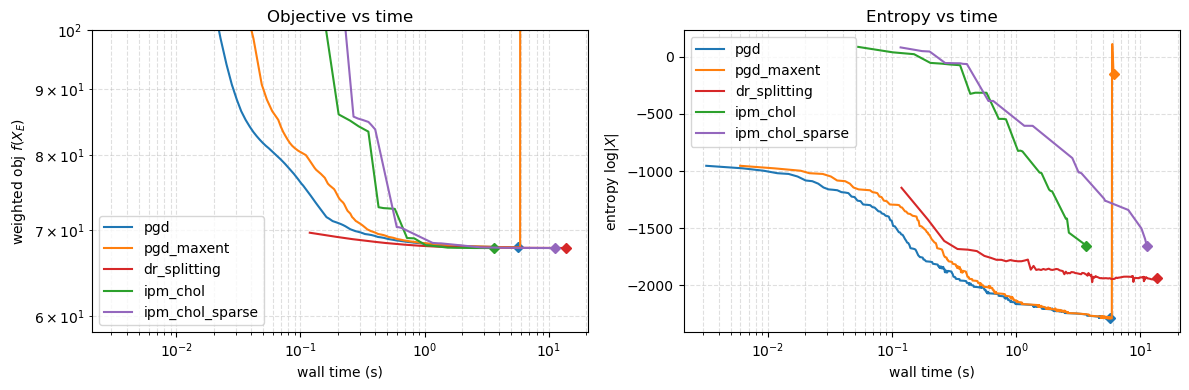

In [5]:
COLORS = {
    'pgd':        'C0',
    'pgd_maxent': 'C1',
    'dr_splitting': 'C3',
    'ipm_chol':   'C2',
    'ipm_chol_sparse': 'C4',
    'clarabel':   'C5',
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, S, h in results:
    t   = [e['time'] for e in h]
    obj = [e['obj']  for e in h]
    c   = COLORS[name]
    axes[0].loglog(t, obj, label=name, color=c)
    axes[0].loglog([t[-1]], [obj[-1]], color=c, marker='D', markersize=5, linestyle='none')

    # entropy: filter nans (clarabel only has the final value)
    ent_pairs = [(e['time'], e['entropy']) for e in h if not np.isnan(e['entropy'])]
    if ent_pairs:
        te, ent = zip(*ent_pairs)
        axes[1].semilogx(te, ent, label=name, color=c,
                         linestyle='none' if len(ent_pairs) == 1 else '-')
        axes[1].semilogx([te[-1]], [ent[-1]], color=c, marker='D', markersize=5, linestyle='none')

axes[0].set_xlabel('wall time (s)')
axes[0].set_ylabel(r'weighted obj $f(X_E)$')
axes[0].set_title('Objective vs time')
axes[0].legend()
axes[0].grid(True, which='both', linestyle='--', alpha=0.4)
axes[0].set_ylim(top=1e2)

axes[1].set_xlabel('wall time (s)')
axes[1].set_ylabel(r'entropy $\log|X|$')
axes[1].set_title('Entropy vs time')
axes[1].legend()
axes[1].grid(True, which='both', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## Matrix error visualisation

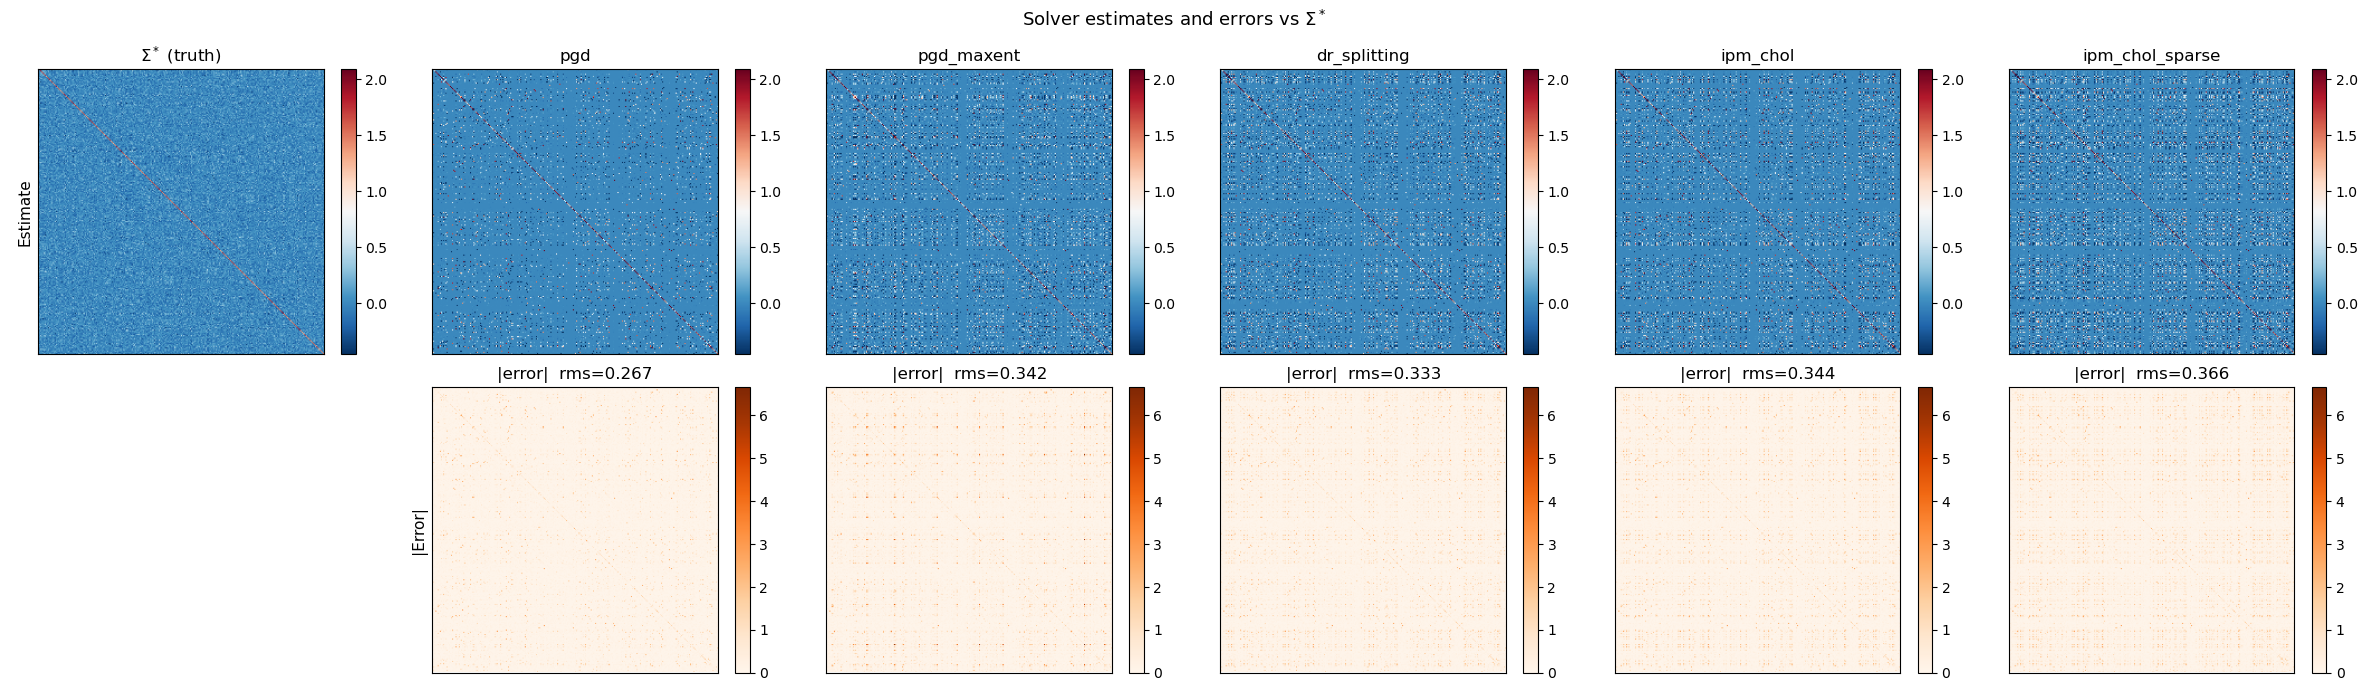

In [6]:
vmin = Sigma_true.min()
vmax = Sigma_true.max()
emax = max(np.abs(Sigma_true - S).max() for _, S, _ in results)
ncols = len(results) + 1

fig, axes = plt.subplots(2, ncols, figsize=(4 * ncols, 7))

# Column 0: truth
im = axes[0, 0].imshow(Sigma_true, vmin=vmin, vmax=vmax, cmap='RdBu_r')
axes[0, 0].set_title(r'$\Sigma^*$ (truth)')
plt.colorbar(im, ax=axes[0, 0], fraction=0.046)
axes[1, 0].axis('off')

# Solver columns
for col, (name, S, h) in enumerate(results, start=1):
    im1 = axes[0, col].imshow(S, vmin=vmin, vmax=vmax, cmap='RdBu_r')
    axes[0, col].set_title(name)
    plt.colorbar(im1, ax=axes[0, col], fraction=0.046)

    err = np.abs(Sigma_true - S)
    im2 = axes[1, col].imshow(err, vmin=0, vmax=emax, cmap='Oranges')
    axes[1, col].set_title(f'|error|  rms={np.sqrt(np.mean(err**2)):.3f}')
    plt.colorbar(im2, ax=axes[1, col], fraction=0.046)

for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])

axes[0, 0].set_ylabel('Estimate', fontsize=11)
axes[1, 1].set_ylabel('|Error|', fontsize=11)

plt.suptitle(r'Solver estimates and errors vs $\Sigma^*$', fontsize=13)
plt.tight_layout()
plt.show()